# Performing WPT and visualise statistical metrics of nodesusing a graph
Here we use a graph presentation to display the results of WPT.

In [1]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

In [2]:

%matplotlib inline
sys.path.append("..")

from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.postprocess import plotting as plot
from wavelet_transform.utils.extensions import sci_form
from wavelet_transform.test import plotting as test_plot

import matplotlib.pyplot as plt
import scipy.signal as sig



### Parameters

Specify parameters for synthetic data and wavelet transform

In [3]:
amp_sin_waves = 1 # amplitude of the sine waves added together to form the signal
sampling_rate = 50e6
phase = 0

frequency = 2e6

frequencies = [frequency] # create list of frequencies for synthetic data
time_period = 1/frequency
signal_duration = 10*time_period # duration of the signal is 10 times the test frequency
delay = 0#2*time_period # signal starts 2 time periods late
end = signal_duration#8*time_period # signal ends 2 time periods early

gaussian_noise_std = 0.01 # set the standard devaition of the noise

# generate data
data, t_plot = sd.sound_wave(
    amp_sin_waves, frequencies, phase, signal_duration, 
    sampling_rate, delay, end
    )

# add noise
gaussian_noise = sd.noise(gaussian_noise_std,signal_duration,sampling_rate)
data += gaussian_noise
data = sig.windows.hann(len(data))*data

# transform parameters
levels = 3
db_order = 10
wavelet = f'db{db_order}'
mode = "symmetric"


### Performing WP transform



In [4]:
# transform
transform_object = wpt.dwpt(data,levels, wavelet, 'constant')
final_level_nodes = transform_object.get_level(levels)
dwt_nodes = transform_object.dwt_results() # the dwt results can be extracted from the dwpt

# calculate energy
transform_object.calc_frequencies(sampling_rate)

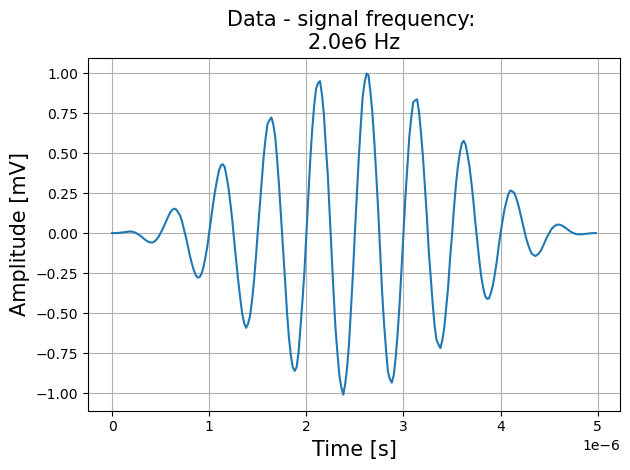

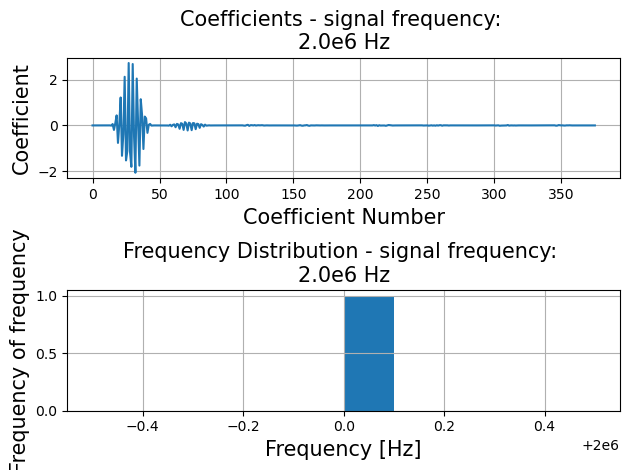

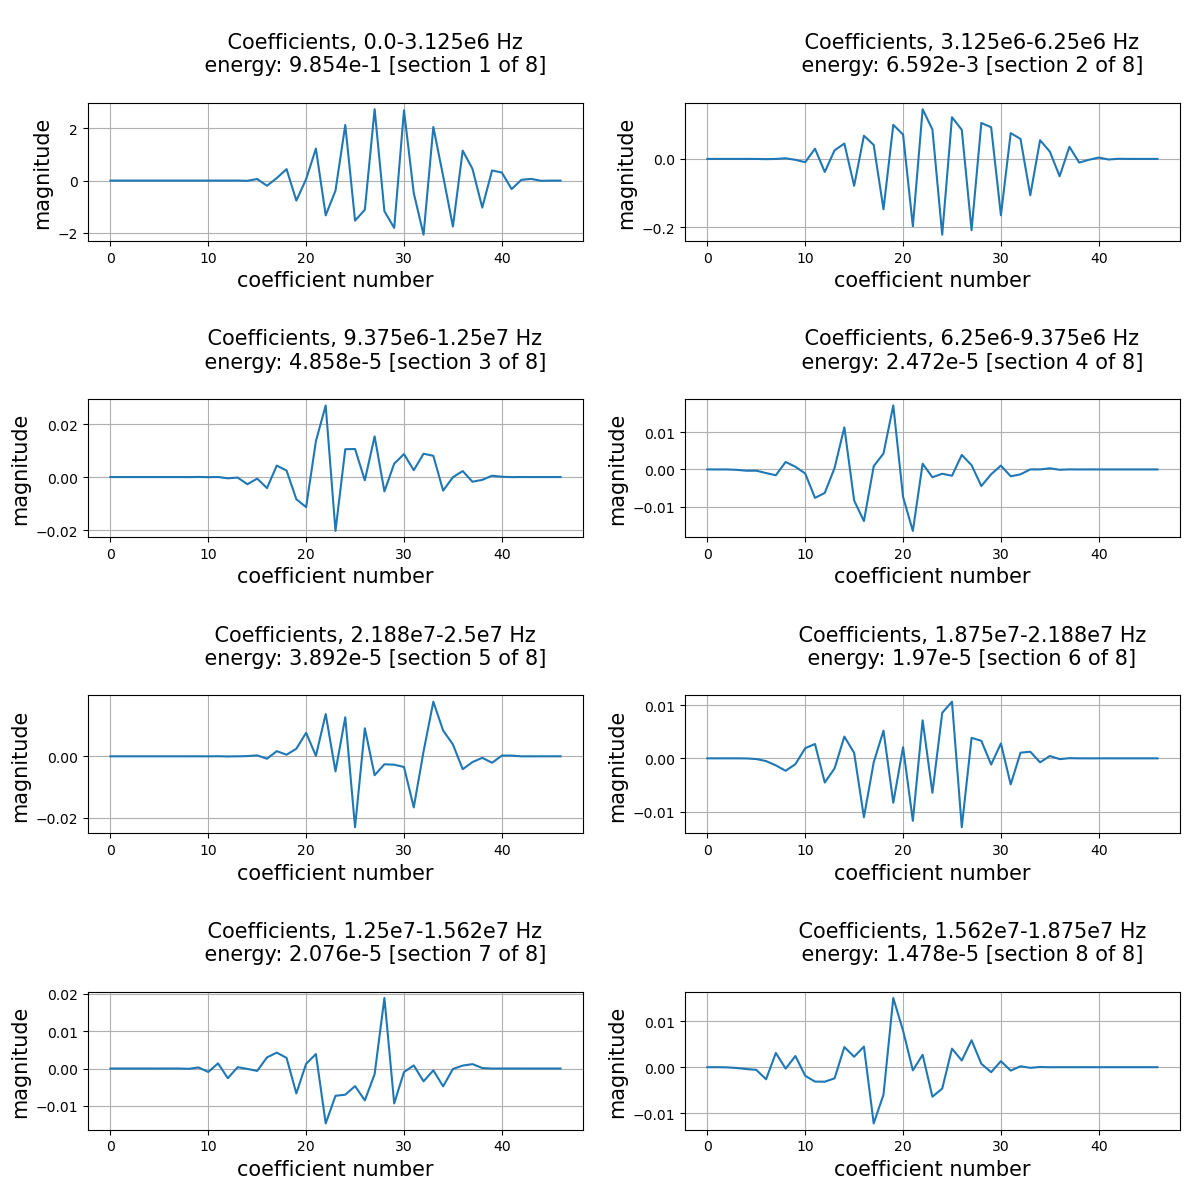

In [5]:
# set title
f = sci_form(frequency)
title = f"- signal frequency: \n{f} Hz"

# plot everything
plot.full_plot(
    final_level_nodes, data, t_plot, sampling_rate, 
    title, frequencies
    )

Calculating crest factor and energy

Wavelet transform

In [6]:
import pandas as pd

# Set display options
pd.set_option("display.max_rows", None)  # Show all rows
pd.set_option("display.max_columns", None)  # Show all columns


# WPT transform
tr_ob = wpt.dwpt(data, levels, wavelet, mode)
tr_ob.calc_frequencies(sampling_rate)

tr_ob.info(level=levels, order="freq").head()

,node number,energy,kurtosis,crest factor,skewness,frequency range
0,0,0.985429,4.397640,0.414354,0.658211,"(0.0, 3.125e6)"
1,1,0.006753,3.884498,0.244341,-1.012183,"(3.125e6, 6.25e6)"
2,3,0.000026,6.956319,2.086198,-0.038771,"(6.25e6, 9.375e6)"
3,2,0.000049,6.940753,3.245011,0.714439,"(9.375e6, 1.25e7)"
4,6,0.000021,9.793621,3.806559,0.755232,"(1.25e7, 1.562e7)"


### Heisenberg visualisation

Making the heisenberg plot of the dwpt transform

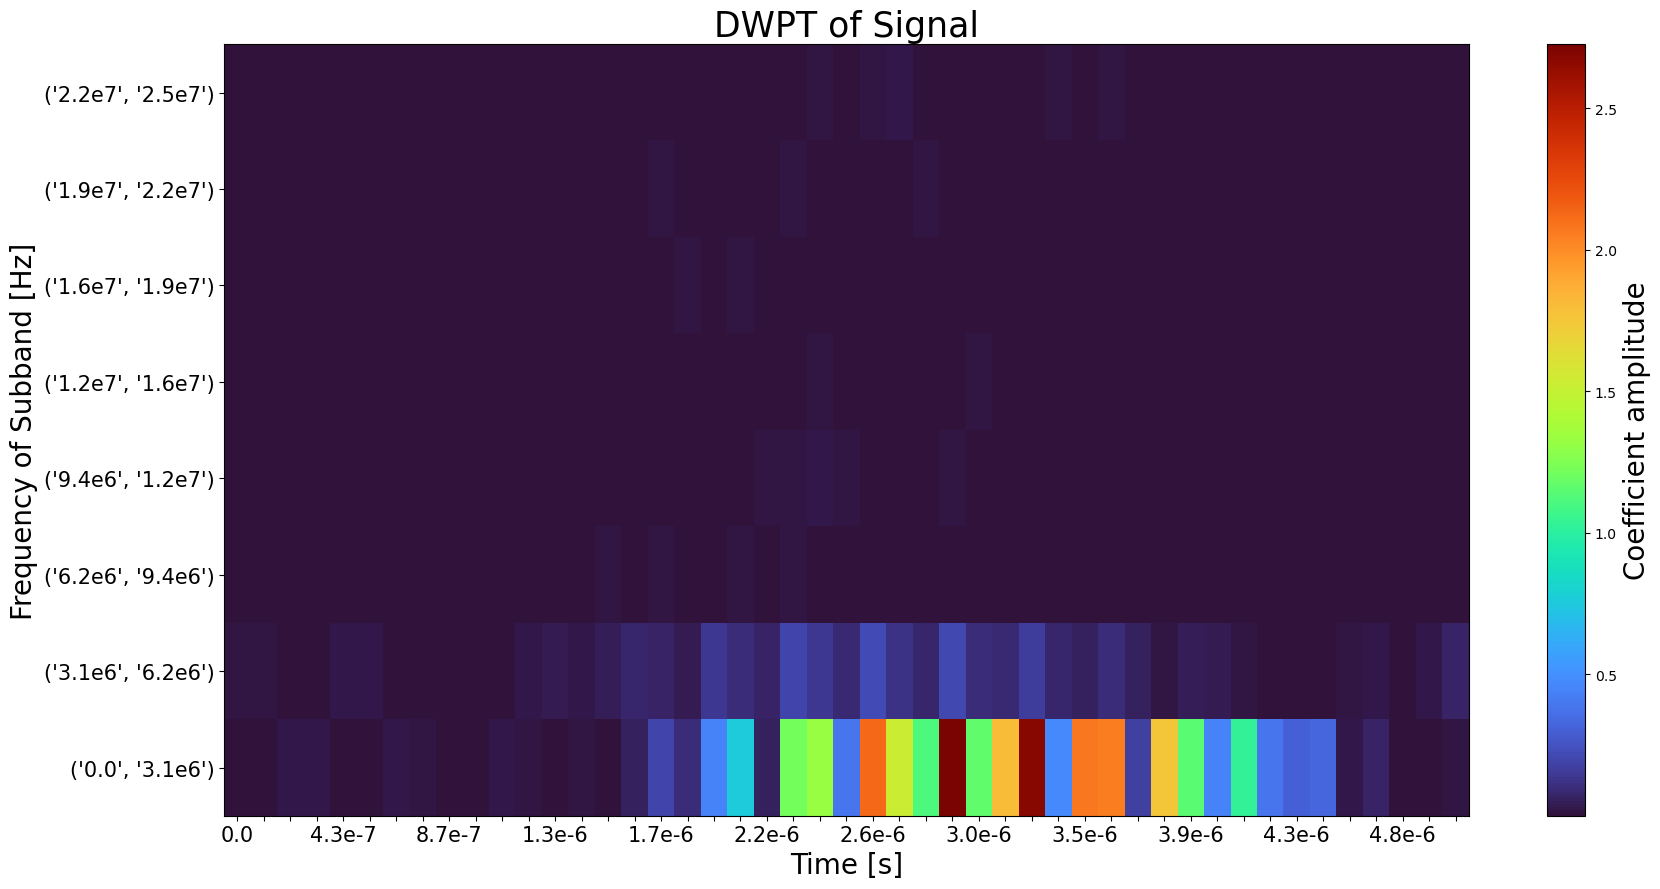

In [7]:
plot.heisenberg(tr_ob, max(t_plot))

In [16]:
for node in tr_ob.info(level=2,order='natural')['node number']:
    print(node)

0
1
2
3


In [21]:
graph_node = []
for i in range(1,levels):
    for node in tr_ob.info(level=i,order='natural')['node number']:
        graph_node.append( (i, node, tr_ob.info(level=i,order='freq').loc[node] ) )
        
        
graph_node[0][:2]

(1, 0)

In [9]:
tr_ob.info(level=i,order='freq')['node number']


0    0
1    1
2    3
3    2
Name: node number, dtype: int64

In [10]:
import networkx as nx

In [11]:
G = nx.Graph()

In [12]:
G= nx.from_pandas_edgelist(gr, "node number", "energy")

NameError: name 'gr' is not defined

In [ ]:
# G.add_nodes_from([(0,0,{'energy':gr1.loc[0]['energy']}),
#                   (1,0,{'energy':gr1.loc[1]['energy']}),
#                   (2,{'energy':gr2.loc[0]['energy']}),
#                   (3,{'energy':gr2.loc[1]['energy']}),
#                   (4,{'energy':gr2.loc[2]['energy']}),
#                   (5,{'energy':gr2.loc[3]['energy']}),
#                   ])
# G.add_edges_from([(0,2),(0,3),(1,4),(1,5)])

G.add_nodes_from([( (0,0),{'energy':gr1.loc[0]['energy']}),
                  ( (1,0),{'energy':gr1.loc[1]['energy']})
                  ])
G.add_edges_from([((0,0),(1,0))])


In [ ]:
nx.draw(G, node_size=[ 1E4*nx.get_node_attributes(G, 'energy')[v] for v in G], with_labels=True)
plt.show()

In [ ]:
gr.loc[0]['energy']